<a href="https://colab.research.google.com/github/VanshikaJain2105/Wine-Quality-Prediction/blob/main/Wine_Quality_Prediction_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Wine Quality Prediction System

**Goal:** Predict whether a wine has a recorded quality rating of 7 or higher using its 11 chemical properties

**Workflow:** Data audit → target definition → train/test split → EDA → feature importance → scaling and PCA → cross-validation → tuning → final test evaluation → prediction and model export

#Importing Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score, roc_auc_score, make_scorer,
    classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)


RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

In [4]:
df=pd.read_csv("/content/winequality.csv")

In [5]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [7]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [8]:
display(df.isna().sum())

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [10]:
print('Duplicates:', df.duplicated().sum())

Duplicates: 240


In [11]:
df.dtypes

,0
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


In [12]:
df.shape

(1599, 12)

In [13]:
df = df.drop_duplicates().reset_index(drop=True)
print('Cleaned shape:', df.shape)

Cleaned shape: (1359, 12)


threshold with a Boolean comparison: quality >= 7 returns True or False and astype(int) turns these into 1 and 0

0 = Not high quality (score below 7)

1 = High quality (score at least 7)

In [14]:
df['quality_label'] = (df['quality'] >= 7).astype(int)
X = df.drop(columns=['quality', 'quality_label'])
y = df['quality_label']

In [16]:
display(y.value_counts().sort_index())

,count
quality_label,
0,1175
1,184


In [17]:
print('Identical predictor rows remaining:', X.duplicated().sum())

Identical predictor rows remaining: 0


## Train-test split
We reserve 20% for the final test and 80% for development.

`stratify=y` maintains approximately the same class proportions; it does not balance classes

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=RANDOM_STATE, stratify=y)

train = df.loc[X_train.index].copy()

print('Training:', X_train.shape, 'Testing:', X_test.shape)

display(y_train.value_counts(normalize=True).sort_index())
assert set(X_train.index).isdisjoint(X_test.index)

Training: (1087, 11) Testing: (272, 11)


,proportion
quality_label,
0,0.864765
1,0.135235


#EDA - Exploratory data Analysis

### Target distribution and class imbalance
A count plot shows the frequency of each rating and binary category

If most wines belong to class 0, a model that always predicts class 0 can have high accuracy without finding any high-quality wines. We therefore also measure precision, recall and F1

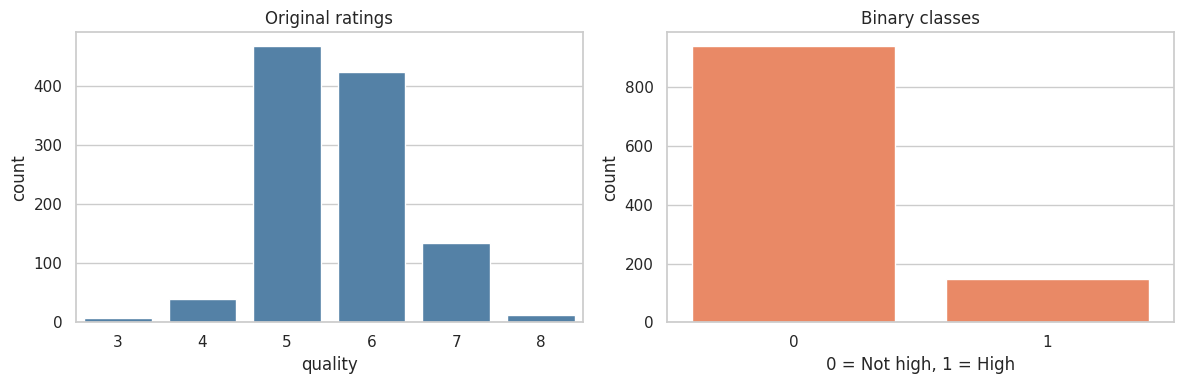

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.countplot(data=train, x='quality', ax=axes[0], color='steelblue')
axes[0].set_title('Original ratings')

sns.countplot(data=train, x='quality_label', ax=axes[1], color='coral')
axes[1].set(title='Binary classes', xlabel='0 = Not high, 1 = High')

plt.tight_layout()
plt.show()

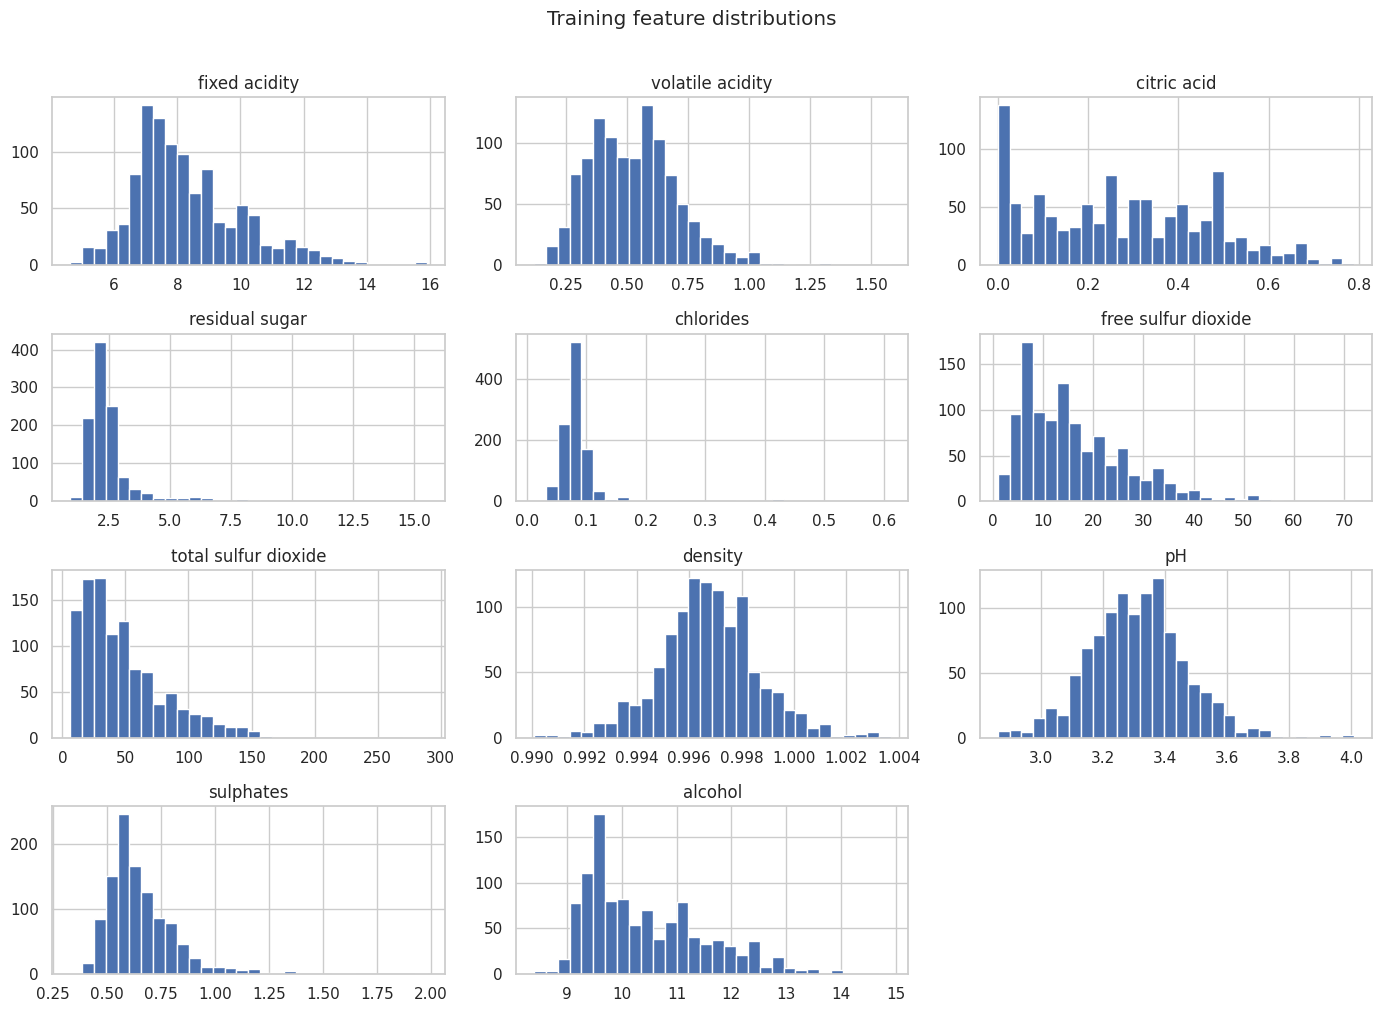

In [21]:
X_train.hist(figsize=(14,10), bins=30, edgecolor='white')
plt.suptitle('Training feature distributions', y=1.01)
plt.tight_layout(); plt.show()

### Pairplots and boxplots
Pairplots show pairwise scatter plots and diagonal distributions. We select four features for readability.

`hue` colours classes differently

Boxplots compare medians and spread between classes. Overlapping distributions suggest that a single feature alone may not separate classes well. Points outside whiskers are not necessarily errors.

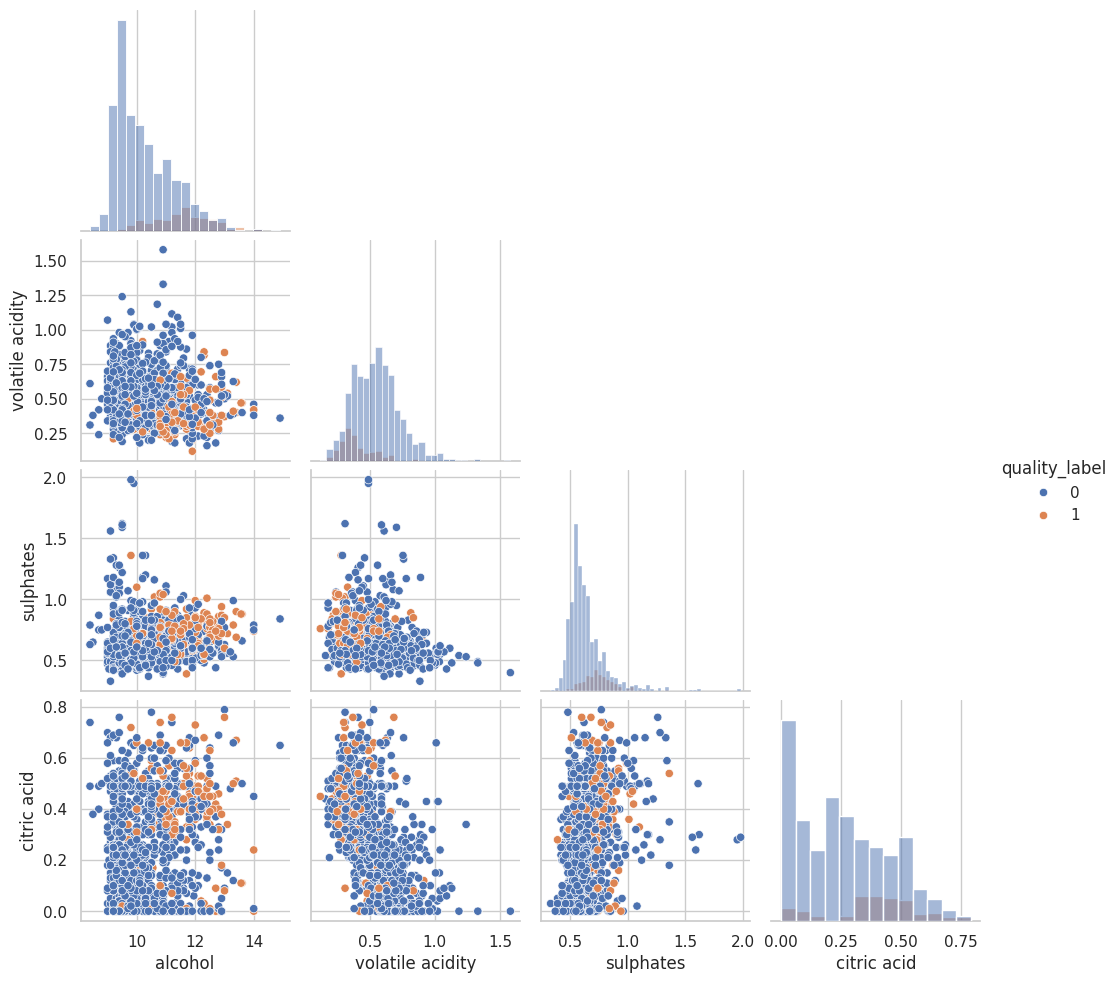

In [23]:
selected = ['alcohol','volatile acidity','sulphates','citric acid']
sns.pairplot(train[selected + ['quality_label']], hue='quality_label', diag_kind='hist', corner=True)
plt.show()

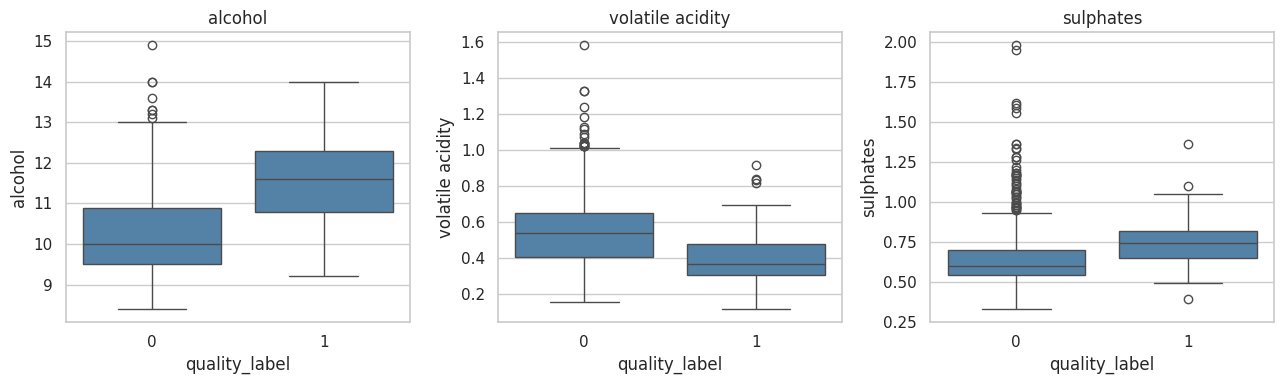

In [24]:
fig, axes = plt.subplots(1,3,figsize=(13,4))

for ax, col in zip(axes, selected[:3]):
    sns.boxplot(data=train, x='quality_label', y=col, ax=ax, color='steelblue')
    ax.set_title(col)

plt.tight_layout()

plt.show()

### Correlation analysis

Pearson correlation ranges from -1 to +1 and describes linear association

Positive means variables tend to increase together

negative means they tend to move oppositely


The heatmap shows all pairwise correlations. Since the matrix is symmetric, a Boolean mask hides its upper triangle.

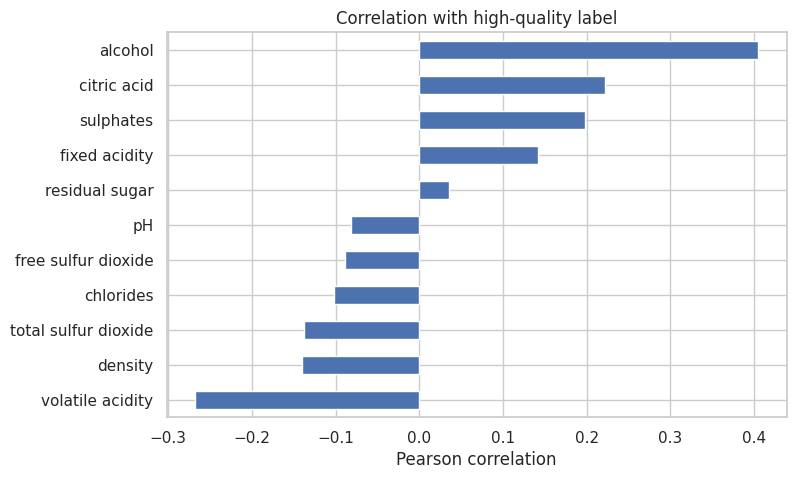

In [27]:
corr = train.drop(columns='quality').corr()
target_corr = corr['quality_label'].drop('quality_label').sort_values()
target_corr.plot.barh(figsize=(8,5), title='Correlation with high-quality label')
plt.xlabel('Pearson correlation'); plt.show()
mask = np.triu(np.ones_like(corr, dtype=bool))

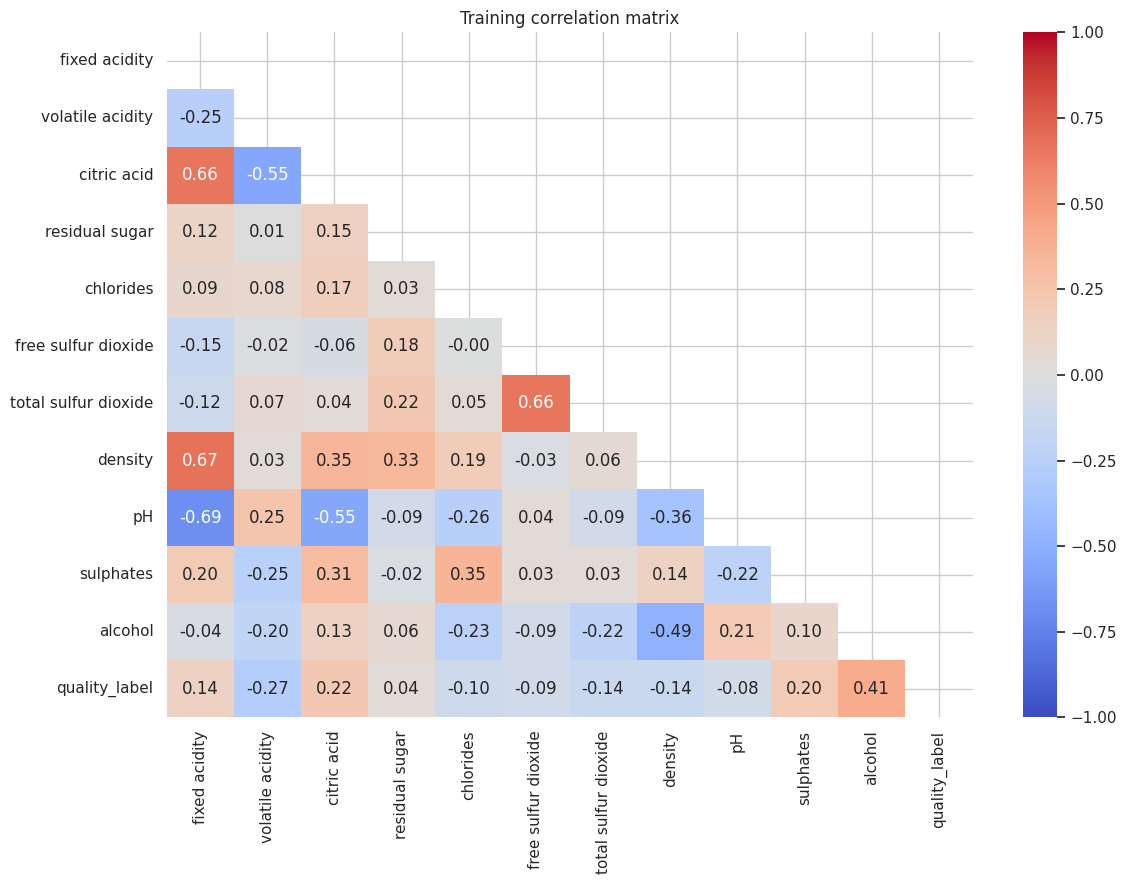

In [26]:
plt.figure(figsize=(12,9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)

plt.title('Training correlation matrix')
plt.tight_layout()
plt.show()

## Random Forest feature importance
Feature importance measures the normalised decrease in impurity contributed by each predictor across trees

In [28]:
importance_model = RandomForestClassifier(n_estimators=200, criterion='entropy', random_state=RANDOM_STATE, n_jobs=2)
importance_model.fit(X_train, y_train)
importance = pd.Series(importance_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(importance.to_frame('Importance'))


,Importance
alcohol,0.180566
sulphates,0.132385
volatile acidity,0.101597
citric acid,0.091063
density,0.087100
total sulfur dioxide,0.083704
fixed acidity,0.074860
chlorides,0.068488
free sulfur dioxide,0.064221
pH,0.061136


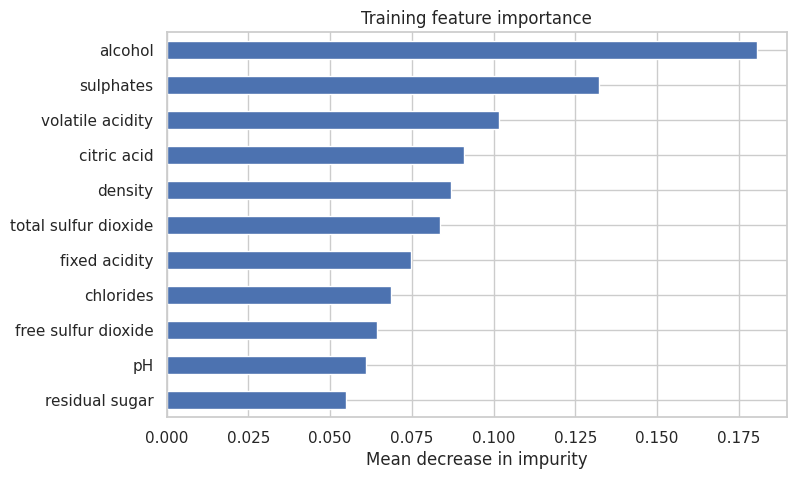

In [30]:
importance.sort_values().plot.barh(figsize=(8,5), title='Training feature importance')
plt.xlabel('Mean decrease in impurity')
plt.show()

## Standardisation and PCA
### StandardScaler
Features have different units and ranges. Scaling is important for SVM, regularised Logistic Regression and PCA.

Standardisation uses

$z=(x-\mu)/\sigma$

where the mean and standard deviation are learned from training data

 `fit_transform` learns and applies the transformation; `transform` applies existing learned statistics. Never fit a scaler on test data. Random Forest without PCA does not need scaling

### Principal Component Analysis
PCA is a dimensionality reduction technique that combines existing features into fewer new features called principal components (PCs)
- PC1 captures the maximum variation in the data
- PC2 captures the next highest variation in a perpendicular direction
- Explained variance tells us how much of the original data variation each component captures
PCA is an unsupervised technique because it does not use target labels

In this project, we compare three approaches:
- All 11 original features
- 4 principal components
- Enough components to retain 95% of the total variance

This helps us understand whether reducing the number of features improves model performance or removes useful information.

PCA is fitted separately inside each cross-validation fold to prevent data leakage

In [31]:
scaler_demo = StandardScaler()
X_scaled = scaler_demo.fit_transform(X_train)
pca_demo = PCA().fit(X_scaled)
variance = pca_demo.explained_variance_ratio_
cumulative = np.cumsum(variance)
display(pd.DataFrame({'PC':np.arange(1,len(variance)+1),'Variance':variance,'Cumulative':cumulative}).round(4))


,PC,Variance,Cumulative
0,1,0.2803,0.2803
1,2,0.1752,0.4555
2,3,0.1413,0.5968
3,4,0.1120,0.7089
4,5,0.0869,0.7957
5,6,0.0578,0.8535
6,7,0.0542,0.9077
7,8,0.0383,0.9460
8,9,0.0319,0.9779
9,10,0.0168,0.9947


In [32]:
print('Variance retained by four PCs:', round(cumulative[3],4))
print('PCs needed for 95% variance:', np.searchsorted(cumulative,.95)+1)


Variance retained by four PCs: 0.7089
PCs needed for 95% variance: 9


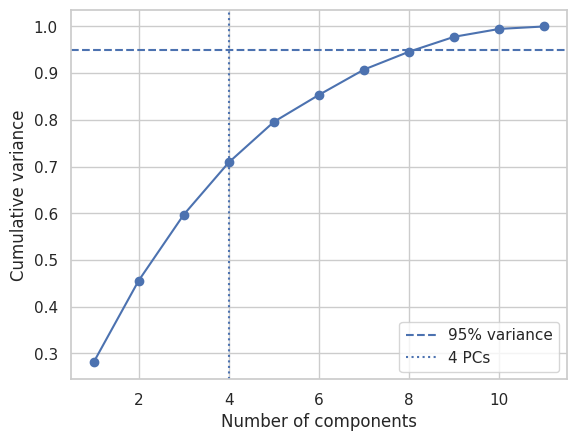

In [34]:
plt.plot(np.arange(1,len(variance)+1), cumulative, marker='o')
plt.axhline(.95, linestyle='--', label='95% variance')
plt.axvline(4, linestyle=':', label='4 PCs')
plt.xlabel('Number of components'); plt.ylabel('Cumulative variance')
plt.legend()
plt.show()

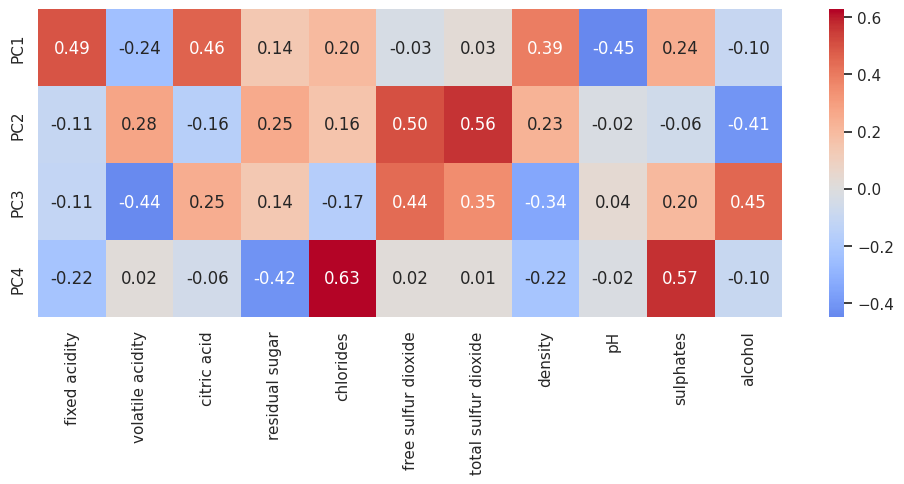

In [35]:
loadings = pd.DataFrame(pca_demo.components_[:4], columns=X_train.columns, index=['PC1','PC2','PC3','PC4'])

plt.figure(figsize=(12,4))
sns.heatmap(loadings, annot=True, fmt='.2f', center=0, cmap='coolwarm')
plt.show()


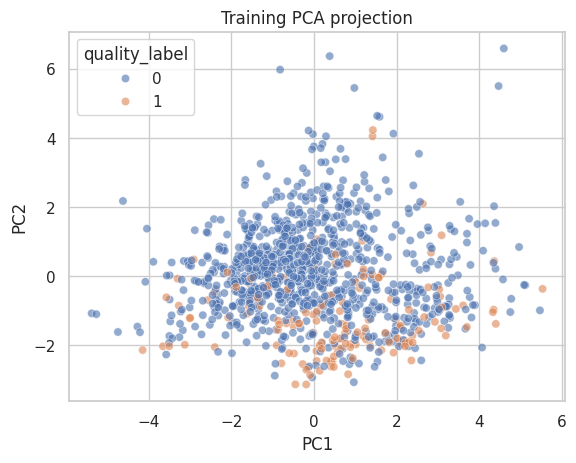

In [36]:
projection = pd.DataFrame(pca_demo.transform(X_scaled)[:,:2], columns=['PC1','PC2'], index=X_train.index)
projection['quality_label'] = y_train
sns.scatterplot(data=projection, x='PC1', y='PC2', hue='quality_label', alpha=.6)
plt.title('Training PCA projection')
plt.show()

#Classification models and metrics

In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {'accuracy':'accuracy', 'balanced_accuracy':'balanced_accuracy',
           'precision':make_scorer(precision_score,zero_division=0),
           'recall':make_scorer(recall_score,zero_division=0),
           'f1':make_scorer(f1_score,zero_division=0), 'average_precision':'average_precision'}



In [38]:
def pipeline_for(model, representation='Original', scale=True):

    # Decide whether to apply scaling
    if scale == True or representation != 'Original':
        scaling = StandardScaler()
    else:
        scaling = 'passthrough'

    # Decide whether to apply PCA
    if representation == 'PCA 4':
        reduction = PCA(n_components=4)

    elif representation == 'PCA 95%':
        reduction = PCA(n_components=0.95)

    else:
        reduction = 'passthrough'

    # Combine all the steps
    return Pipeline([('scale', scaling),('pca', reduction),('model', model)])

In [39]:
baseline = pipeline_for(DummyClassifier(strategy='most_frequent'),scale=False)
base_cv = cross_validate(baseline,X_train,y_train,cv=cv,scoring=scoring)

In [43]:
results = {}

for metric in scoring:
    scores = base_cv['test_' + metric]
    results[metric] = scores.mean()

display(pd.DataFrame(results, index=['Dummy CV']))

,accuracy,balanced_accuracy,precision,recall,f1,average_precision
Dummy CV,0.86477,0.5,0.0,0.0,0.0,0.13523


In [44]:
# Define machine learning models
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000,random_state=RANDOM_STATE),
    'Linear SVM': SVC(kernel='linear'),
    'RBF SVM': SVC(kernel='rbf'),
    'Random Forest': RandomForestClassifier(n_estimators=100,criterion='entropy',random_state=RANDOM_STATE,n_jobs=2)
}


# Store results and pipeline configurations
rows = []
pipelines = {}

representations = ['Original', 'PCA 4', 'PCA 95%']
weights = [None, 'balanced']


In [46]:
from sklearn.base import clone
# Experiment with each model

for name, estimator in models.items():
    # Try different feature representations
    for representation in representations:
        # Try normal and balanced class weights
        for weight in weights:
            # Create a fresh copy of the model
            model = clone(estimator)
            # Set class weights
            model.set_params(class_weight=weight)
            # Decide whether scaling is required
            if name == 'Random Forest':
                scale = False
            else:
                scale = True
            # Create the pipeline
            pipe = pipeline_for(model,representation,scale)

            # Name the weight configuration
            if weight == 'balanced':
                weight_name = 'Balanced'
            else:
                weight_name = 'None'

            # Save the pipeline configuration
            pipelines[(name, representation, weight_name)] = pipe

            # Perform cross-validation
            scores = cross_validate(pipe,X_train,y_train,cv=cv,scoring=scoring,n_jobs=1)

            # Store experiment details
            row = {
                'Model': name,
                'Features': representation,
                'Weights': weight_name
            }

            # Calculate average evaluation scores
            for metric in scoring:
                row[metric] = scores['test_' + metric].mean()

            # Calculate F1 score variation
            row['f1_std'] = scores['test_f1'].std()

            # Save experiment results
            rows.append(row)

In [47]:
# Create the final results table
results = pd.DataFrame(rows)

# Sort by highest F1 score
results = results.sort_values('f1',ascending=False)

results = results.reset_index(drop=True)

display(results.round(3))

,Model,Features,Weights,accuracy,balanced_accuracy,precision,recall,f1,average_precision,f1_std
0,RBF SVM,PCA 95%,Balanced,0.806,0.790,0.390,0.768,0.516,0.531,0.022
1,RBF SVM,Original,Balanced,0.806,0.787,0.389,0.761,0.515,0.524,0.022
2,Logistic Regression,PCA 95%,Balanced,0.790,0.801,0.376,0.816,0.514,0.498,0.016
3,Logistic Regression,Original,Balanced,0.786,0.799,0.371,0.816,0.508,0.493,0.017
4,Linear SVM,Original,Balanced,0.776,0.798,0.360,0.829,0.500,0.492,0.012
5,Linear SVM,PCA 95%,Balanced,0.773,0.788,0.353,0.809,0.491,0.497,0.022
6,Logistic Regression,PCA 4,Balanced,0.776,0.782,0.355,0.789,0.489,0.481,0.009
7,Linear SVM,PCA 4,Balanced,0.773,0.780,0.351,0.789,0.485,0.484,0.022
8,RBF SVM,PCA 4,Balanced,0.776,0.764,0.348,0.748,0.475,0.484,0.011
9,Random Forest,Original,None,0.877,0.641,0.574,0.319,0.407,0.532,0.088


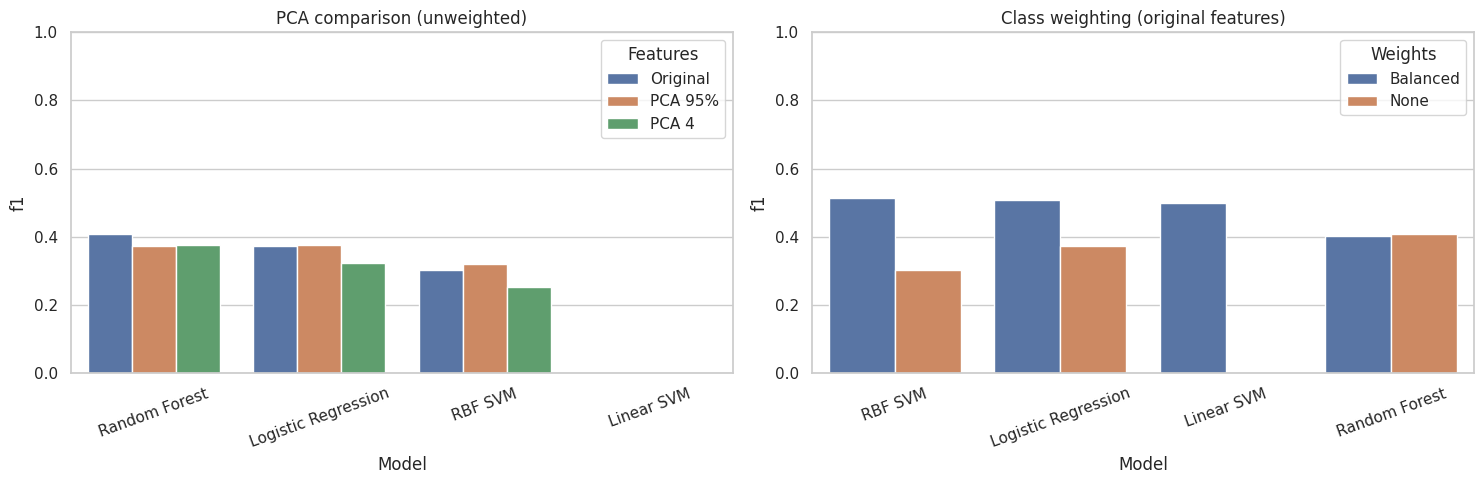

Best untuned configuration: {'Model': 'RBF SVM', 'Features': 'PCA 95%', 'Weights': 'Balanced'}
Mean CV F1: 0.5164


In [48]:
fig, axes = plt.subplots(1,2,figsize=(15,5))
sns.barplot(data=results[results.Weights=='None'],x='Model',y='f1',hue='Features',ax=axes[0])
sns.barplot(data=results[results.Features=='Original'],x='Model',y='f1',hue='Weights',ax=axes[1])
for ax,title in zip(axes,['PCA comparison (unweighted)','Class weighting (original features)']):
    ax.set_title(title)
    ax.tick_params(axis='x',rotation=20)
    ax.set_ylim(0,1)
plt.tight_layout()
plt.show()
best = results.iloc[0]
print('Best untuned configuration:',best[['Model','Features','Weights']].to_dict())
print('Mean CV F1:',round(best.f1,4))

#Hyperparameter Tuning

In [49]:
# Parameters to experiment with
param_grid = {
    'model__C': [0.5, 1, 5, 10],
    'model__gamma': ['scale', 0.05, 0.2],
    'model__class_weight': [None, 'balanced']
}

# Retrieve the best pipeline
key = (best.Model, best.Features, best.Weights)

# Hyperparameter tuning
search = GridSearchCV(pipelines[key],param_grid,scoring='f1',cv=cv)

search.fit(X_train, y_train)

# Store the best trained model
final_model = search.best_estimator_

print('Best parameters:', search.best_params_)
print('Best F1 score:', search.best_score_)

Best parameters: {'model__C': 10, 'model__class_weight': 'balanced', 'model__gamma': 'scale'}
Best F1 score: 0.5195353713345737


#Final Model Evaluation

After hyperparameter tuning, we evaluate our best model on the unseen test dataset using accuracy, balanced accuracy, precision, recall and F1 score. We also generate a confusion matrix to understand where our model makes incorrect predictions.

Accuracy: 0.8088235294117647
Balanced Accuracy: 0.7641173087981599
Precision: 0.3880597014925373
Recall: 0.7027027027027027
F1 Score: 0.5
              precision    recall  f1-score   support

           0       0.95      0.83      0.88       235
           1       0.39      0.70      0.50        37

    accuracy                           0.81       272
   macro avg       0.67      0.76      0.69       272
weighted avg       0.87      0.81      0.83       272



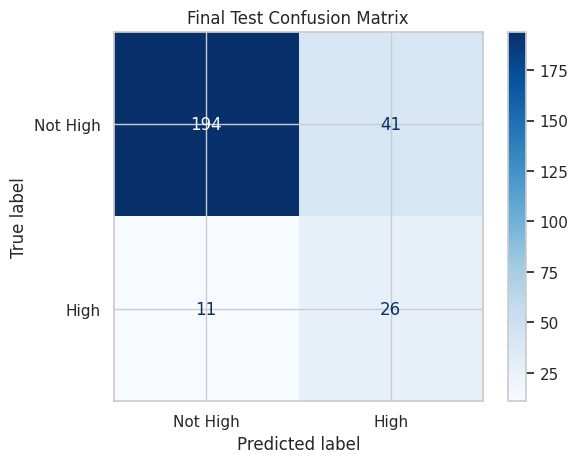

In [50]:
# Make predictions on the test dataset
y_pred = final_model.predict(X_test)

# Evaluate the model
print('Accuracy:', accuracy_score(y_test, y_pred))
print('Balanced Accuracy:', balanced_accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred, zero_division=0))
print('Recall:', recall_score(y_test, y_pred, zero_division=0))
print('F1 Score:', f1_score(y_test, y_pred, zero_division=0))

# Classification report
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Not High', 'High'],
    cmap='Blues'
)

plt.title('Final Test Confusion Matrix')
plt.show()

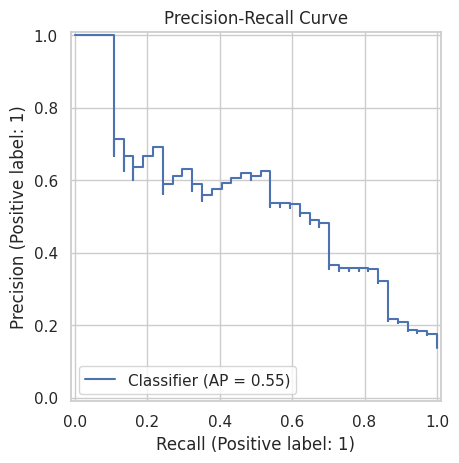

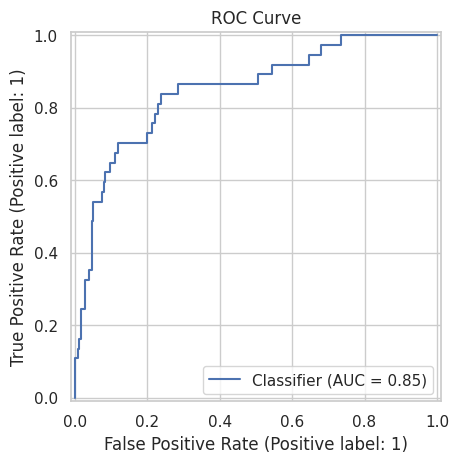

In [52]:
scores = final_model.decision_function(X_test)

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, scores)
plt.title('Precision-Recall Curve')
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions(y_test, scores)
plt.title('ROC Curve')
plt.show()

In [55]:
sample = X_test.iloc[[0]]
display(sample.T)
labels = {0:'Not high quality',1:'High quality'}
print('Predicted:',labels[int(final_model.predict(sample)[0])])
print('Actual:',labels[int(y_test.loc[sample.index[0]])])

if hasattr(final_model,'predict_proba'):
    print('Estimated probability (not calibrated):',round(final_model.predict_proba(sample)[0,1],3))
else:
    print('Decision score (not probability):',round(final_model.decision_function(sample)[0],3))

,1117
fixed acidity,8.00000
volatile acidity,1.18000
citric acid,0.21000
residual sugar,1.90000
chlorides,0.08300
free sulfur dioxide,14.00000
total sulfur dioxide,41.00000
density,0.99532
pH,3.34000
sulphates,0.47000


Predicted: Not high quality
Actual: Not high quality
Decision score (not probability): -1.567


In [56]:
errors = X_test.assign(Actual=y_test,Predicted=y_pred)
display(errors[errors.Actual != errors.Predicted].head(10))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Actual,Predicted
1037,8.2,0.400,0.31,1.9,0.082,8.0,24.0,0.99600,3.24,0.69,10.6,0,1
631,6.4,0.865,0.03,3.2,0.071,27.0,58.0,0.99500,3.61,0.49,12.7,0,1
1135,6.6,0.580,0.02,2.4,0.069,19.0,40.0,0.99387,3.38,0.66,12.6,0,1
239,10.9,0.370,0.58,4.0,0.071,17.0,65.0,0.99935,3.22,0.78,10.1,0,1
453,9.8,0.250,0.49,2.7,0.088,15.0,33.0,0.99820,3.42,0.90,10.0,0,1
446,10.7,0.400,0.48,2.1,0.125,15.0,49.0,0.99800,3.03,0.81,9.7,0,1
754,7.1,0.470,0.00,2.2,0.067,7.0,14.0,0.99517,3.40,0.58,10.9,0,1
894,9.3,0.500,0.36,1.8,0.084,6.0,17.0,0.99704,3.27,0.77,10.8,0,1
498,12.3,0.270,0.49,3.1,0.079,28.0,46.0,0.99930,3.20,0.80,10.2,0,1
991,8.8,0.450,0.43,1.4,0.076,12.0,21.0,0.99551,3.21,0.75,10.2,0,1


In [58]:
print('Best model:', best.Model)
print('Best features:', best.Features)
print('Best parameters:', search.best_params_)
print('Best CV F1 score:', round(search.best_score_, 3))

print('\nPerformance by feature representation:')
print(results.groupby('Features')['f1'].max())

print('\nPerformance by class weights:')
print(results.groupby('Weights')['f1'].max())

Best model: RBF SVM
Best features: PCA 95%
Best parameters: {'model__C': 10, 'model__class_weight': 'balanced', 'model__gamma': 'scale'}
Best CV F1 score: 0.52

Performance by feature representation:
Features
Original    0.514648
PCA 4       0.488539
PCA 95%     0.516382
Name: f1, dtype: float64

Performance by class weights:
Weights
Balanced    0.516382
None        0.407415
Name: f1, dtype: float64


====================Thankyouuuu=======================